Dataset Shape: (1000, 16)

First 5 records:
   Age  Gender  ...   Chest Pain Type  Heart Disease
0   75  Female  ...   Atypical Angina              1
1   48    Male  ...    Typical Angina              0
2   53    Male  ...   Atypical Angina              1
3   69  Female  ...  Non-anginal Pain              0
4   62  Female  ...      Asymptomatic              0

[5 rows x 16 columns]

Processed Data Shape:
(1000, 27)


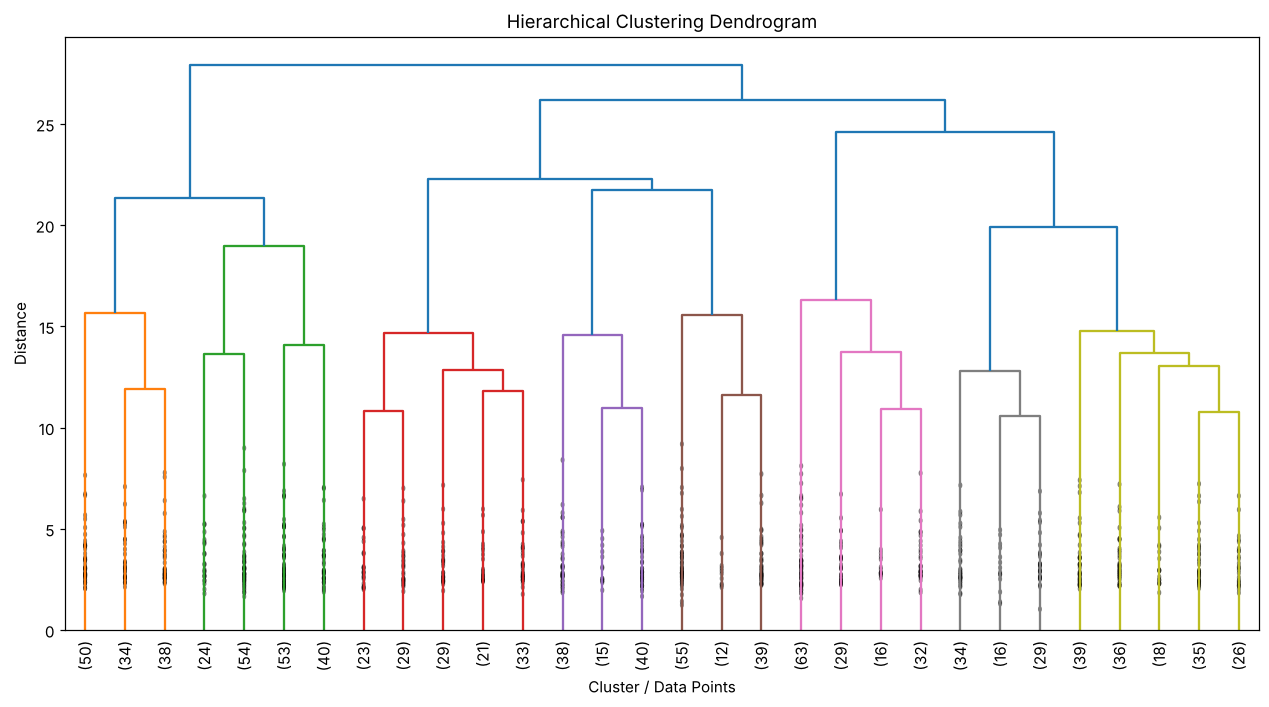

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

from scipy.cluster.hierarchy import (
    dendrogram,
    linkage
)

df = pd.read_csv("heart_disease_dataset.csv")

print("Dataset Shape:", df.shape)
print("\nFirst 5 records:")
print(df.head())

X = df.drop("Heart Disease", axis=1)

numeric_features = X.select_dtypes(
    include=["int64", "float64"]
).columns

categorical_features = X.select_dtypes(
    include=["object"]
).columns

preprocessor = ColumnTransformer(
    transformers=[
        ("num", StandardScaler(), numeric_features),
        ("cat", OneHotEncoder(handle_unknown="ignore"), categorical_features)
    ]
)

X_processed = preprocessor.fit_transform(X)

# Check whether X_processed is sparse or already a NumPy array
if hasattr(X_processed, "toarray"):
    X_processed = X_processed.toarray()

print("\nProcessed Data Shape:")
print(X_processed.shape)

linked = linkage(
    X_processed,
    method="ward"
)

plt.figure(figsize=(14, 7))

dendrogram(
    linked,
    truncate_mode="lastp",
    p=30,
    leaf_rotation=90,
    leaf_font_size=10,
    show_contracted=True
)

plt.title("Hierarchical Clustering Dendrogram")
plt.xlabel("Cluster / Data Points")
plt.ylabel("Distance")

plt.show()
